In [7]:
import pandas as pd
import numpy as np
import neurokit2 as nk
import os
from datetime import datetime

# Load CSV data
patient = '01Nva-003-1007'
path = f'../data/01NVa_Sepsis/RAW_DATA/{patient}/PPG/'

# List all CSV files in the path
ppg_files = [f for f in os.listdir(path) if f.endswith('.csv')]

# Initialize an empty list to store dataframes
df_list = []

# Loop through each file, read and append to the list
for file in ppg_files:
    # Extract the start time from the filename
    start_time_str = file.split('.')[0]
    start_time = datetime.strptime(start_time_str, "%Y%m%dT%H%M%S")

    # Read the CSV file
    temp_df = pd.read_csv(os.path.join(path, file))

    # Calculate the absolute timestamp based on the starting time of the file
    temp_df["ABSOLUTE_TIMESTAMP_MS"] = temp_df["TIMESTAMP_MS"] + int(start_time.timestamp() * 1000)

    # Extract necessary columns
    temp_df = temp_df[["ABSOLUTE_TIMESTAMP_MS", "PLETH"]]

    # Rename columns for consistency
    temp_df.rename(columns={"ABSOLUTE_TIMESTAMP_MS": "TIMESTAMP_MS", "PLETH": "ppg"}, inplace=True)

    # Set TIMESTAMP_MS as the index
    temp_df.set_index("TIMESTAMP_MS", inplace=True)

    # Resample the data to ensure 10 ms intervals
    # Fill in any missing values using forward fill method
    timestamp_range = pd.RangeIndex(start=temp_df.index.min(), stop=temp_df.index.max() + 10, step=10)
    temp_df = temp_df.reindex(timestamp_range, method='ffill')
    temp_df.index.name = "TIMESTAMP_MS"

    # Reset the index to have TIMESTAMP_MS as a column
    temp_df.reset_index(inplace=True)

    # Append to the list of dataframes
    df_list.append(temp_df)

# Concatenate all dataframes
concatenated_df = pd.concat(df_list, ignore_index=True)

# Remove invalid PPG signals that last for more than 10 seconds (1000 samples at 100 Hz)
invalid_zero_groups = (concatenated_df['ppg'] == 0).astype(int).groupby((concatenated_df['ppg'] != 0).cumsum()).cumsum()
concatenated_df = concatenated_df[~((concatenated_df['ppg'] == 0) & (invalid_zero_groups > 1000))]

# Extract PPG signal
df_ppg = concatenated_df.copy()
ppg_signal = df_ppg["ppg"].values

# Clean the PPG signal before computing quality
ppg_cleaned = nk.ppg_clean(ppg_signal, sampling_rate=100)

# Compute PPG Quality Index on the cleaned signal
ppg_quality = nk.ppg_quality(ppg_cleaned, sampling_rate=100)

# Add cleaned PPG and Quality Index to df_ppg
df_ppg["PPG_Clean"] = ppg_cleaned
df_ppg["PPG_Quality"] = ppg_quality

# Only keep rows with Quality Index greater than 0.5 and update timestamps accordingly
df_ppg_filtered = df_ppg[df_ppg["PPG_Quality"] > 0.5].reset_index(drop=True)

# Compute time differences to identify gaps
df_ppg_filtered["Time_Diff"] = df_ppg_filtered["TIMESTAMP_MS"].diff().fillna(10)

# Identify gaps (assuming sampling rate is 100 Hz, i.e., 10 ms between samples)
df_ppg_filtered["Gap"] = df_ppg_filtered["Time_Diff"] > 10

# Assign segment IDs to continuous high-quality data
df_ppg_filtered["Segment_ID"] = df_ppg_filtered["Gap"].cumsum()

# Calculate the start time for elapsed time calculation
start_time_ms = df_ppg_filtered["TIMESTAMP_MS"].iloc[0]

# Initialize list to store HRV metrics
hrv_list = []

# Change window size from 10 seconds to 2 minutes (120 seconds)
window_size = 120 * 100  # 2 minutes window with 100 Hz sampling rate

# Loop through each continuous segment
for segment_id, segment_df in df_ppg_filtered.groupby("Segment_ID"):
    segment_length = len(segment_df)
    num_windows = segment_length // window_size
    for i in range(num_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        window_df = segment_df.iloc[start_idx:end_idx]
        window_signal = window_df["PPG_Clean"].values
        if len(window_signal) == window_size:
            # Process the window to extract HRV metrics
            # Find peaks in the PPG signal
            peaks_dict = nk.ppg_findpeaks(window_signal, sampling_rate=100)
            peaks = peaks_dict["PPG_Peaks"]

            # Ensure there are enough peaks to compute HRV
            if len(peaks) > 2:
                # Compute HRV metrics
                hrv_metrics = nk.hrv(peaks_dict, sampling_rate=100, show=False)
                
                # Add additional PPG features
                # Example: Pulse Amplitude Variability (PAV)
                pulse_amplitudes = window_signal[peaks]
                pav = np.std(pulse_amplitudes) / np.mean(pulse_amplitudes)
                hrv_metrics["PAV"] = pav

                # Calculate elapsed time in seconds from the start time
                time_elapsed_seconds = (window_df.iloc[0]["TIMESTAMP_MS"] - start_time_ms) / 1000.0
                hrv_metrics["Time_Elapsed_Seconds"] = time_elapsed_seconds

                # Collect the hrv_metrics in a list
                hrv_list.append(hrv_metrics)

# Concatenate HRV metrics into a DataFrame
if hrv_list:
    hrv_df = pd.concat(hrv_list, ignore_index=True)
    # Reorder columns for readability
    cols = hrv_df.columns.tolist()
    cols.remove("Time_Elapsed_Seconds")
    hrv_df = hrv_df[["Time_Elapsed_Seconds"] + cols]
    # Save the HRV variables
    hrv_df.to_csv("hrv_variables.csv", index=False)
    print("PPG signal processing and HRV calculation complete.")
else:
    print("No valid HRV data was found in the PPG signal.")


PPG signal processing and HRV calculation complete.


In [6]:
hrv_df

,Time_Elapsed_Seconds,HRV_MeanNN,HRV_SDNN,HRV_SDANN1,HRV_SDNNI1,HRV_SDANN2,HRV_SDNNI2,HRV_SDANN5,HRV_SDNNI5,HRV_RMSSD,...,HRV_ShanEn,HRV_FuzzyEn,HRV_MSEn,HRV_CMSEn,HRV_RCMSEn,HRV_CD,HRV_HFD,HRV_KFD,HRV_LZC,PAV
0,0.00,534.529148,39.038302,NaN,NaN,NaN,NaN,NaN,NaN,51.957190,...,2.395736,0.465108,0.356276,0.991595,1.021200,0.515802,2.076719,1.427017,0.594687,0.054542
1,120.00,534.864865,12.538799,NaN,NaN,NaN,NaN,NaN,NaN,11.514304,...,2.236163,1.103964,1.258769,1.171657,1.121763,0.867478,1.882308,2.528903,0.702200,0.035360
2,288.27,531.780822,14.621443,NaN,NaN,NaN,NaN,NaN,NaN,16.381350,...,2.484297,1.076223,1.101075,1.189305,1.219120,1.082157,1.984494,3.121055,0.781029,0.148896
3,408.27,530.311111,12.478235,NaN,NaN,NaN,NaN,NaN,NaN,11.299494,...,2.231217,1.022387,1.232573,1.161337,1.135152,0.779104,1.927989,2.706637,0.659830,0.048275
4,528.27,521.710526,10.626394,NaN,NaN,NaN,NaN,NaN,NaN,15.943181,...,2.036093,1.240932,1.499862,1.194875,1.150127,1.071289,1.986344,3.407696,0.996289,0.146142
5,648.27,539.590909,18.587468,NaN,NaN,NaN,NaN,NaN,NaN,12.478292,...,2.676966,0.952250,0.896104,1.184802,1.185261,1.025287,1.880787,2.350236,0.778136,0.087505
6,768.27,536.351351,10.495548,NaN,NaN,NaN,NaN,NaN,NaN,12.033137,...,2.103416,1.168880,1.133503,1.095818,1.106720,0.507258,1.942418,3.706051,0.947969,0.065355
7,888.27,534.459459,12.086628,NaN,NaN,NaN,NaN,NaN,NaN,12.201179,...,2.292661,1.049572,1.262447,1.182010,1.250964,0.758842,1.868368,2.695663,0.737310,0.116948
8,1008.27,538.868778,11.040668,NaN,NaN,NaN,NaN,NaN,NaN,9.700047,...,2.144510,1.027409,1.264814,1.209326,1.222583,0.566361,1.851221,3.082982,0.775266,0.058155
9,1128.27,543.013699,12.923728,NaN,NaN,NaN,NaN,NaN,NaN,10.514298,...,2.368177,1.082604,1.295766,1.253078,1.505645,0.594172,1.822735,3.305144,0.710026,0.045293


In [1]:
from dataset_preprocess import *

In [2]:
features, labels = load_excel()

/data2/Projects/vital_sepsis/codes/dataset_preprocess.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  feature_CLI['OXY_START_DAY'] = feature_CLI['OXY_START_DAY'].apply(


PPG signal processing and HRV calculation complete for 01NVa-003-1001.


ValueError: time data '01NVa-003-1002 1' does not match format '%Y%m%dT%H%M%S'

In [10]:
features

,AGE,SEX,HYPERTENSION,MYOCARDIAL_INFARCTION,HEART_FAILURE_GRADE3,ANGINA,HEART_FAILURE_GD4,PERIPH_VASCULAR_DISEASE,CEREBROVASC_DISEASE,CHRONIC_PULM_DISEASE,...,MONITORING_SPO2_slope,MONITORING_SPO2_intercept,MONITORING_SPO2_rmse,MONITORING_SPO2_r2,MONITORING_MAP_mean,MONITORING_MAP_var,MONITORING_MAP_slope,MONITORING_MAP_intercept,MONITORING_MAP_rmse,MONITORING_MAP_r2
USUBJID,,,,,,,,,,,,,,,,,,,,,
003-1001,84,F,Y,N,N,N,N,N,N,N,...,-0.013501,98.020153,1.097365,0.004684,86.365079,119.755606,0.053349,85.742679,10.937885,0.000988
003-1002,39,F,N,N,N,N,N,N,N,N,...,-0.032779,96.746537,1.582492,0.022523,75.320513,51.294707,0.628490,66.835897,5.392214,0.433158
003-1003,30,M,N,N,N,N,N,N,N,N,...,0.249123,94.680702,1.313626,0.338845,77.261905,48.606009,0.175092,75.948718,6.935981,0.010249
003-1004,40,F,N,N,N,N,N,N,N,N,...,-0.050853,98.081437,0.945811,0.139847,91.205128,28.214333,0.013219,91.026667,5.310791,0.000348
003-1005,55,M,N,N,N,N,N,N,N,N,...,-0.011860,98.266542,0.336528,0.075114,86.400000,115.608889,1.205897,70.723333,6.323850,0.654083
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
003-1255,51,F,N,N,N,N,N,N,N,N,...,0.013314,96.958580,1.265656,0.004653,90.260870,180.028565,1.122200,76.794466,11.163239,0.307788
003-1256,65,F,Y,N,N,N,N,N,N,N,...,-0.027728,97.561717,0.763226,0.044081,84.028986,54.849401,0.625494,76.523057,6.134714,0.313854
003-1257,66,M,Y,N,N,N,N,N,N,N,...,-0.281818,93.600000,2.259781,0.134594,78.454545,21.076217,1.051515,72.145455,3.165340,0.524612


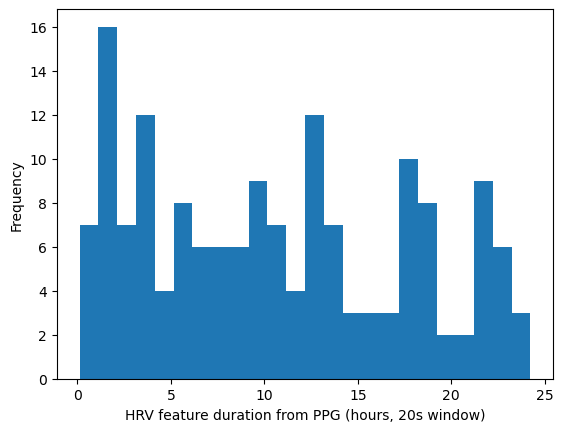

In [13]:
# calculate the length of the HRV features
import os
import pandas
import numpy as np

path = '../data/HRV'
hrv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
length_list = []
for file in hrv_files:
    hrv_df = pandas.read_csv(os.path.join(path, file))
    length_list.append((len(hrv_df)-1)*20/60/60)  # 20 seconds per window, convert to hours

# plot the histogram of the HRV features
import matplotlib.pyplot as plt
plt.hist(length_list, bins=24)
plt.xlabel('HRV feature duration from PPG (hours, 20s window)') 
plt.ylabel('Frequency')
plt.savefig('../figures/hrv_feature_duration.png')
plt.show()